In [ ]:
from pathlib import Path
import time
import numpy as np
import matplotlib.pyplot as plt

from data import load_fashion_mnist, one_hot, CLASS_NAMES
from plotting import plot_confusion, plot_heatmap
from metrics import accuracy, accuracy_se, confusion, per_class_scores, roc_one_vs_rest
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

project_root = Path.cwd().parent if Path.cwd().name == "code" else Path.cwd()
figures_dir = project_root / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

In [2]:
(x_train, y_train), (x_val, y_val), (x_test, y_test) = load_fashion_mnist(seed=2026)
y_test_oh = one_hot(y_test)
print(f"Training set shape: {x_train.shape}")
print(f"Test set shape: {x_test.shape}")

Training set shape: (50000, 784)
Test set shape: (10000, 784)


In [3]:
C_values = [0.01, 0.1, 1.0]
results_c = {}
print(f"C | Validation Accuracy")
for C in C_values:
    model_c = LogisticRegression(solver="saga", max_iter=1000, random_state=2026, C=C)
    model_c.fit(x_train, y_train)
    y_pred_val = model_c.predict(x_val)
    val_acc = accuracy_score(y_val, y_pred_val)
    results_c[C] = val_acc
    print(f"{C} & {val_acc:.4f}")

best_C = max(results_c, key=results_c.get)
print(f"\nBest C: {best_C} with validation accuracy: {results_c[best_C]:.4f}")

C | Validation Accuracy
0.01 & 0.8516
0.1 & 0.8583
1.0 & 0.8527

Best C: 0.1 with validation accuracy: 0.8583


In [4]:
model_logreg = LogisticRegression(solver="saga", max_iter=1000, random_state=2026, C=best_C)
start_time = time.perf_counter()
model_logreg.fit(x_train, y_train)
train_time = time.perf_counter() - start_time
n_params = model_logreg.coef_.size + model_logreg.intercept_.size
print(f"Training time: {train_time:.4f} seconds")
print(f"Number of parameters: {n_params}")

Training time: 184.6732 seconds
Number of parameters: 7850


In [5]:
y_pred_logreg = model_logreg.predict(x_test)
y_proba_test = model_logreg.predict_proba(x_test)
y_test_oh = one_hot(y_test)

print(f"Test accuracy: {accuracy(y_test, y_pred_logreg):.4f} ± {accuracy_se(y_test, y_pred_logreg):.4f}")

precision, recall, f1 = per_class_scores(y_test, y_pred_logreg)
print("\nPer-class metrics:")
print(f"{'Class':<20} {'Precision':<12} {'Recall':<12} {'F1':<12}")
for i, class_name in enumerate(CLASS_NAMES):
    print(f"{class_name:<20} {precision[i]:<12.4f} {recall[i]:<12.4f} {f1[i]:<12.4f}")

Test accuracy: 0.8444 ± 0.0036

Per-class metrics:
Class                Precision    Recall       F1          
T-shirt/top          0.8042       0.8130       0.8086      
Trouser              0.9765       0.9560       0.9661      
Pullover             0.7273       0.7360       0.7316      
Dress                0.8321       0.8720       0.8516      
Coat                 0.7385       0.7570       0.7477      
Sandal               0.9454       0.9170       0.9310      
Shirt                0.6319       0.5700       0.5994      
Sneaker              0.9080       0.9380       0.9228      
Bag                  0.9288       0.9390       0.9339      
Ankle boot           0.9376       0.9460       0.9418      


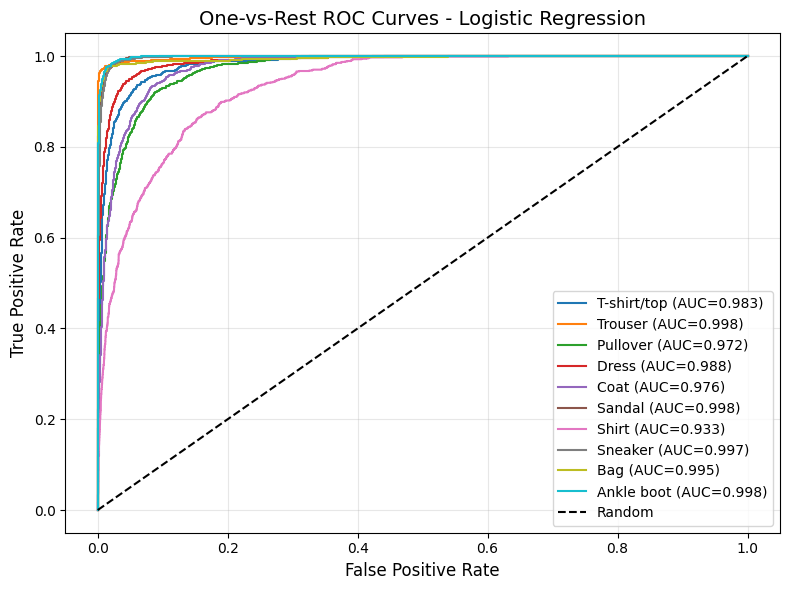

In [6]:
curves, aucs = roc_one_vs_rest(y_test, y_proba_test)
fig, ax = plt.subplots(figsize=(8, 6))
for k in range(len(CLASS_NAMES)):
    fpr, tpr = curves[k]
    ax.plot(fpr, tpr, label=f"{CLASS_NAMES[k]} (AUC={aucs[k]:.3f})")
ax.plot([0, 1], [0, 1], "k--", label="Random")
ax.set_xlabel("False Positive Rate", fontsize=12)
ax.set_ylabel("True Positive Rate", fontsize=12)
ax.set_title("One-vs-Rest ROC Curves - Logistic Regression", fontsize=14)
ax.legend(fontsize=10, loc="lower right")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(figures_dir / "logistic_regression_roc.pdf", bbox_inches="tight")
plt.show()

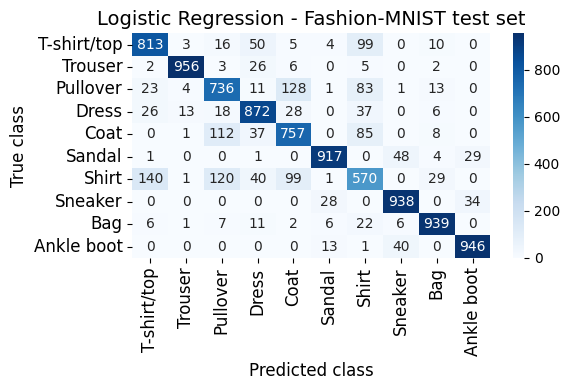

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
cm = confusion(y_test, y_pred_logreg)
plot_confusion(cm, class_labels=CLASS_NAMES, title="Fashion-MNIST test set", ax=ax)
ax.set_title("Logistic Regression - Fashion-MNIST test set", fontsize=14)
ax.xaxis.label.set_size(12)
ax.yaxis.label.set_size(12)
ax.tick_params(axis="both", labelsize=12)
plt.tight_layout()
fig.savefig(figures_dir / "logistic_regression_confusion_matrix.pdf", bbox_inches="tight")
plt.show()